# Chapter 12 :  Parallelizing Neural Network Training with PyTorch

In [1]:
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")
print(f"GPU name: {torch.cuda.get_device_name(0)}")

# Test a simple tensor on GPU
if torch.cuda.is_available():
    x = torch.rand(3, 3).cuda()
    print(f"Tensor on GPU: {x.device}")

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA version: 12.1
GPU name: NVIDIA T1200 Laptop GPU
Tensor on GPU: cuda:0


In [3]:
import torch 
import numpy as np 

np.set_printoptions(precision=3)

a = [1 ,2 , 3]
b = np.array([4,5,6] , dtype = np.int32)
t_a = torch.tensor(a)
t_b = torch.tensor(b)

print(t_a)
print(t_b)



tensor([1, 2, 3])
tensor([4, 5, 6], dtype=torch.int32)


In [7]:
t_ones = torch.ones(4 ,5)
print(t_ones.shape)
print(t_ones)

torch.Size([4, 5])
tensor([[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]])


In [9]:
rand_tensor = torch.rand(2,3)
print(rand_tensor)

tensor([[0.0850, 0.4322, 0.7209],
        [0.7404, 0.2808, 0.3025]])


In [11]:
t_a_new = t_a.to(torch.int64)
print(t_a_new.dtype)

torch.int64


In [12]:
t = torch.rand(3 ,5)

t_tr = torch.transpose(t , 0 , 1)

print(t.shape , "---->" , t_tr.shape)

torch.Size([3, 5]) ----> torch.Size([5, 3])


In [14]:
t = torch.zeros(3,6,6)

t_reshape = t.reshape(2,-1)

print(t_reshape.shape)

torch.Size([2, 54])


In [16]:
t = torch.zeros(1,2,1,4,1)

t_sqz = torch.squeeze(t,2)

print(t.shape , "----->" , t_sqz.shape)

torch.Size([1, 2, 1, 4, 1]) -----> torch.Size([1, 2, 4, 1])


In [17]:
torch.manual_seed(1)

t1 = 2*torch.rand(5,2) - 1 
t2 = torch.normal(mean=0 , std = 1 , size=(5,2))

In [23]:
t2 @ t1.reshape(2,5)

tensor([[ 0.8658, -0.5243,  0.1924,  0.5013, -0.8951],
        [-0.9383,  0.4120, -0.5811, -0.3367,  0.4764],
        [-0.6006,  0.5222,  0.2444, -0.5573,  1.1218],
        [ 0.4448,  0.0493,  0.8585, -0.1638,  0.5470],
        [ 0.0054,  0.0840,  0.2094, -0.1123,  0.2703]])

In [19]:
t3 = torch.multiply(t1 , t2)
print(t3)


tensor([[ 0.4426, -0.3114],
        [ 0.0660, -0.5970],
        [ 1.1249,  0.0150],
        [ 0.1569,  0.7107],
        [-0.0451, -0.0352]])


### Understanding axis

axis = 0 --> Along the rows 

axis = 1 --> Across the columns

axis = -1 --> Last dimension 

In [25]:
t4 = torch.mean(t1 , axis=1)
print(t4)

tensor([ 0.0369,  0.1378, -0.1709,  0.1515,  0.0083])


In [27]:
t5 = torch.matmul(t1 , torch.transpose(t2 , 0 , 1))

print(t5)

tensor([[ 0.1312,  0.3860, -0.6267, -1.0096, -0.2943],
        [ 0.1647, -0.5310,  0.2434,  0.8035,  0.1980],
        [-0.3855, -0.4422,  1.1399,  1.5558,  0.4781],
        [ 0.1822, -0.5771,  0.2585,  0.8676,  0.2132],
        [ 0.0330,  0.1084, -0.1692, -0.2771, -0.0804]])


In [28]:
t6 = torch.matmul(torch.transpose(t1 , 0 , 1) , t2)

print(t6)

tensor([[ 1.7453,  0.3392],
        [-1.6038, -0.2180]])


In [32]:
#  the torch.linalg.norm() function is useful for computing the Lp norm of a tensor. For ex
# ample, we can calculate the L2 norm of t1
norm1 = torch.linalg.norm(t1 , ord=2 , dim=1)
print(norm1)


norm_numpy = np.sqrt(np.sum(np.square(t1.numpy()), axis=1))
print(norm_numpy)

tensor([0.6785, 0.5078, 1.1162, 0.5488, 0.1853])
[0.678 0.508 1.116 0.549 0.185]


### Split, stack, and concatenate tensors

In [38]:
torch.manual_seed(1)

t = torch.rand(15)

print(t)


tensor([0.7576, 0.2793, 0.4031, 0.7347, 0.0293, 0.7999, 0.3971, 0.7544, 0.5695,
        0.4388, 0.6387, 0.5247, 0.6826, 0.3051, 0.4635])


In [39]:
t_splits = torch.chunk(t , 5)
[item.numpy() for item in t_splits]

[array([0.758, 0.279, 0.403], dtype=float32),
 array([0.735, 0.029, 0.8  ], dtype=float32),
 array([0.397, 0.754, 0.57 ], dtype=float32),
 array([0.439, 0.639, 0.525], dtype=float32),
 array([0.683, 0.305, 0.464], dtype=float32)]

In [43]:
t_splits = torch.split(t , split_size_or_sections=[3, 3, 3, 3, 3])
[item.numpy() for item in t_splits]

[array([0.758, 0.279, 0.403], dtype=float32),
 array([0.735, 0.029, 0.8  ], dtype=float32),
 array([0.397, 0.754, 0.57 ], dtype=float32),
 array([0.439, 0.639, 0.525], dtype=float32),
 array([0.683, 0.305, 0.464], dtype=float32)]

In [44]:
A = torch.ones(3)
B = torch.zeros(2)
C = torch.cat([A,B] , axis = 0)

print(C)

tensor([1., 1., 1., 0., 0.])


In [45]:
A = torch.ones(5)
B = torch.zeros(5)

C = torch.stack([A,B] , axis=1)

print(C)

tensor([[1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.]])


## Building input pipelines in PyTorch

In [46]:
from torch.utils.data import DataLoader 

t = torch.arange(6 , dtype=torch.float32)
data_loader = DataLoader(t)

In [47]:
for item in data_loader: 
    print(item)

tensor([0.])
tensor([1.])
tensor([2.])
tensor([3.])
tensor([4.])
tensor([5.])


In [50]:
data_loader = DataLoader(t , batch_size=3 , drop_last=False)

for i, batch in enumerate(data_loader , 1): 
    print(f"batch {i}, {batch}")

batch 1, tensor([0., 1., 2.])
batch 2, tensor([3., 4., 5.])


In [53]:
torch.manual_seed(1)
t_x = torch.rand([4,3] , dtype=torch.float32)
t_y = torch.arange(4)


In [60]:
from torch.utils.data import Dataset 

class JointDataset(Dataset): 
    def __init__(self , X , y): 
        self.X = X
        self.y = y

    def __len__(self): 
        return self.X.shape[0]
    
    def __getitem__(self, index):
        return self.X[index] , self.y[index]
    
        

In [61]:
dataset = JointDataset(t_x , t_y)

for example in dataset: 
    print(example)
    break

(tensor([0.7576, 0.2793, 0.4031]), tensor(0))


In [66]:
torch.manual_seed(1)
data_loader = DataLoader(dataset=dataset , batch_size=2 , shuffle=True)
for epoch in range(2):
    print(f"epoch {epoch+1}")
    for i , batch in enumerate(data_loader , 1):
        print(f"batch {i} , x: {batch[0]} , y: {batch[1]}")

epoch 1
batch 1 , x: tensor([[0.3971, 0.7544, 0.5695],
        [0.7576, 0.2793, 0.4031]]) , y: tensor([2, 0])
batch 2 , x: tensor([[0.7347, 0.0293, 0.7999],
        [0.4388, 0.6387, 0.5247]]) , y: tensor([1, 3])
epoch 2
batch 1 , x: tensor([[0.7576, 0.2793, 0.4031],
        [0.3971, 0.7544, 0.5695]]) , y: tensor([0, 2])
batch 2 , x: tensor([[0.7347, 0.0293, 0.7999],
        [0.4388, 0.6387, 0.5247]]) , y: tensor([1, 3])


## Creating a dataset from files on your local storage disk

In [69]:
import pathlib 

imgdir_path = pathlib.Path('cat_dog_images')
file_list = sorted([str(path) for path in imgdir_path.glob('*.jpg')])
print(file_list)

['cat_dog_images\\cat-01.jpg', 'cat_dog_images\\cat-02.jpg', 'cat_dog_images\\cat-03.jpg', 'cat_dog_images\\dog-01.jpg', 'cat_dog_images\\dog-02.jpg', 'cat_dog_images\\dog-03.jpg']


In [73]:
import matplotlib.pyplot as plt 
import os 
from PIL import Image 

fig = plt.Figure(figsize=(10,5))

for i,file in enumerate(file_list): 
    img = Image.open(file)
    print("Images shape: " , np.array(img).shape)
    ax = fig.add_subplot(2,3,i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(img)
    ax.set_title(os.path.basename(file),size=15)

plt.tight_layout()
plt.show()


Images shape:  (900, 1200, 3)
Images shape:  (900, 1200, 3)
Images shape:  (900, 742, 3)
Images shape:  (800, 1200, 3)
Images shape:  (800, 1200, 3)
Images shape:  (900, 1200, 3)


<Figure size 640x480 with 0 Axes>

In [74]:
labels = [1 if 'dog' in os.path.basename(file) else 0 for file in file_list]

print(labels)

[0, 0, 0, 1, 1, 1]


In [81]:
class ImageDataset(Dataset): 

    def __init__(self , file_list , labels) : 
        self.file_list = file_list
        self.labels = labels

    def __getitem__(self , index): 
        file = self.file_list[index]
        label = self.labels[index]

        return file , label
    
    def __len__(self): 
        return len(self.labels)

Image_dataset = ImageDataset(file_list , labels)

for file , label in Image_dataset: 

    print(file , label)

cat_dog_images\cat-01.jpg 0
cat_dog_images\cat-02.jpg 0
cat_dog_images\cat-03.jpg 0
cat_dog_images\dog-01.jpg 1
cat_dog_images\dog-02.jpg 1
cat_dog_images\dog-03.jpg 1


###  Fetching available datasets from the torchvision.datasets library

In [ ]:
import torchvision 

image_path = './img_align_celeba/'
celeba_dataset = torchvision.datasets.CelebA(image_path , split = 'train' , target_type='attr' , download=False)

RuntimeError: Dataset not found or corrupted. You can use download=True to download it

### Building a Linear Regression model 

In [13]:
import numpy as np 
import matplotlib.pyplot as plt 
import torch 

In [2]:
X_train = np.arange(10, dtype = 'float32').reshape((10,1))
X_train

array([[0.],
       [1.],
       [2.],
       [3.],
       [4.],
       [5.],
       [6.],
       [7.],
       [8.],
       [9.]], dtype=float32)

In [3]:
y_train = np.array([1.0, 1.3, 3.1, 2.0, 5.0,6.3, 6.6,7.4, 8.0,9.0], dtype='float32')
y_train

array([1. , 1.3, 3.1, 2. , 5. , 6.3, 6.6, 7.4, 8. , 9. ], dtype=float32)

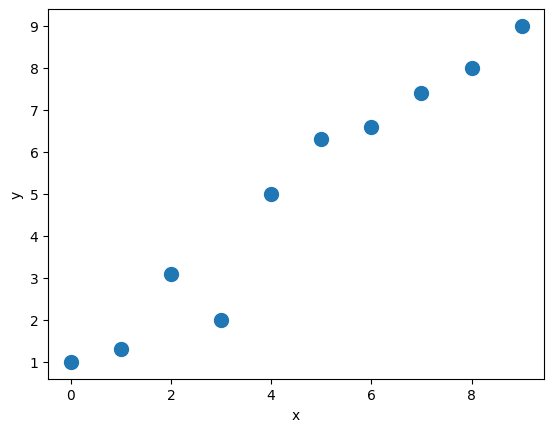

In [4]:
plt.plot(X_train , y_train , 'o' , markersize = 10)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

#### The data !!! 

In [5]:
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader 

X_train_norm = (X_train - np.mean(X_train)) / np.std(X_train)

X_train_norm = torch.from_numpy(X_train_norm)

y_train = torch.from_numpy(y_train)

train_ds = TensorDataset(X_train_norm , y_train)

batch_size = 1

train_d1 = DataLoader(train_ds , batch_size , shuffle = True)

#### The Model !!!!

In [6]:
torch.manual_seed(1)
weight = torch.randn(1)
weight.requires_grad_()
bias = torch.zeros(1,requires_grad=True)

def model(xb): 

    return xb @ weight + bias 

def loss_fn(input , target): 
    return (input - target).pow(2).mean()



#### The Training Fuction !!!! 

In [7]:
learning_rate = 0.001
num_epochs = 200 
log_epochs = 10 
for epoch in range(num_epochs): 
    for x_batch , y_batch in train_d1: 
        pred = model(x_batch)
        loss = loss_fn(pred , y_batch)
        loss.backward()

    with torch.no_grad(): 
        weight -= weight.grad * learning_rate
        bias -= bias.grad * learning_rate
        weight.grad.zero_()
        bias.grad.zero_()

    if epoch % log_epochs == 0: 
        print(f"Epoch {epoch} loss {loss.item():.4f}")




Epoch 0 loss 46.5720
Epoch 10 loss 27.1502
Epoch 20 loss 1.6446
Epoch 30 loss 14.4571
Epoch 40 loss 11.7827
Epoch 50 loss 6.4122
Epoch 60 loss 0.6339
Epoch 70 loss 3.1562
Epoch 80 loss 2.0100
Epoch 90 loss 0.3107
Epoch 100 loss 0.7625
Epoch 110 loss 1.0024
Epoch 120 loss 0.0232
Epoch 130 loss 0.5138
Epoch 140 loss 0.0741
Epoch 150 loss 1.8712
Epoch 160 loss 0.0007
Epoch 170 loss 0.0850
Epoch 180 loss 0.0634
Epoch 190 loss 0.0012


In [8]:
print('Final Parameters:', weight.item(), bias.item())

Final Parameters: 2.670930862426758 4.88258695602417


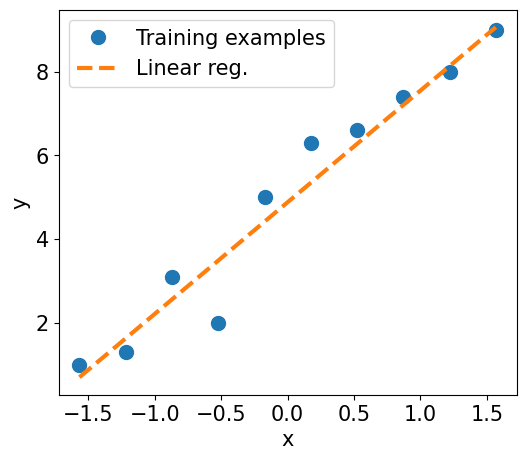

In [9]:
X_test = np.linspace(0, 9, num=100, dtype='float32').reshape(-1, 1)
X_test_norm = (X_test - np.mean(X_train)) / np.std(X_train)
X_test_norm = torch.from_numpy(X_test_norm)
y_pred = model(X_test_norm).detach().numpy()
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1)
plt.plot(X_train_norm, y_train, 'o', markersize=10)
plt.plot(X_test_norm, y_pred, '--', lw=3)
plt.legend(['Training examples', 'Linear reg.'], fontsize=15)
ax.set_xlabel('x', size=15)
ax.set_ylabel('y', size=15)
ax.tick_params(axis='both', which='major', labelsize=15)
plt.show()

In [10]:
import torch.nn as nn 

loss_fn = nn.MSELoss(reduction="mean")
input_size = 1
output_size = 1
model = nn.Linear(input_size , output_size)
optimizer = torch.optim.SGD(model.parameters() , lr = learning_rate)

for epoch in range(num_epochs): 
    for x_batch , y_batch in train_d1: 

        pred = model(x_batch)[:,0]

        loss = loss_fn(pred , y_batch)

        loss.backward()

        optimizer.step()

        optimizer.zero_grad()

    if epoch % log_epochs == 0: 

        print(f"Epoch {epoch} Loss {loss.item() :.4f}")

print('Final Parameters:', model.weight.item(), model.bias.item())

Epoch 0 Loss 24.6684
Epoch 10 Loss 29.1377
Epoch 20 Loss 20.9207
Epoch 30 Loss 0.1257
Epoch 40 Loss 12.4922
Epoch 50 Loss 1.7845
Epoch 60 Loss 7.6425
Epoch 70 Loss 2.5606
Epoch 80 Loss 0.0157
Epoch 90 Loss 0.7548
Epoch 100 Loss 0.8412
Epoch 110 Loss 0.4923
Epoch 120 Loss 0.0823
Epoch 130 Loss 0.0794
Epoch 140 Loss 0.0891
Epoch 150 Loss 0.0973
Epoch 160 Loss 0.1043
Epoch 170 Loss 0.1103
Epoch 180 Loss 0.0009
Epoch 190 Loss 0.0764
Final Parameters: 2.6496422290802 4.87706995010376


### Building a multilayer perceptron for classifying flowers in the Iris dataset

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import numpy as np
import torch 
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader 

iris = load_iris()

batch_size = 2

X = iris["data"]
y = iris["target"]

In [20]:


X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=1./3 , random_state=1)

X_train_norm = (X_train - np.mean(X_train)) / np.std(X_train)
X_train_norm = torch.from_numpy(X_train_norm).float()
y_train = torch.from_numpy(y_train) 
train_ds = TensorDataset(X_train_norm, y_train)
torch.manual_seed(1)

train_dl = DataLoader(train_ds, batch_size, shuffle=True)

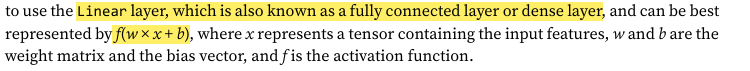

In [28]:
import torch.nn as nn 

class Module(nn.Module): 

    def __init__(self , input_size , hidden_size , output_size):

        super().__init__()

        self.layer1 = nn.Linear(input_size , hidden_size)
        self.layer2 = nn.Linear(hidden_size , output_size)

    def forward(self , x): 

        x = self.layer1(x)
        x = nn.Sigmoid()(x)
        x = self.layer2(x)
        x = nn.Softmax(dim=1)(x)

        return x 
    
input_size = X_train_norm.shape[1]
hidden_size = 16
output_size = 3

model = Module(input_size , hidden_size , output_size)


In [29]:
learning_rate = 0.001 
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters() , lr=learning_rate)


In [30]:
num_epochs = 100 
loss_hist = [0] * num_epochs 
accuracy_hist = [0] * num_epochs 

for epoch in range(num_epochs): 

    for x_batch , y_batch in train_dl: 

        pred = model(x_batch)
        loss = loss_fn(pred , y_batch)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()


        loss_hist[epoch] += loss.item() * y_batch.size(0)
        is_correct = (torch.argmax(pred , dim=1) == y_batch).float()
        accuracy_hist[epoch] += is_correct.mean()
        
    loss_hist[epoch] /= len(train_dl.dataset)
    accuracy_hist[epoch] /=len(train_dl.dataset)

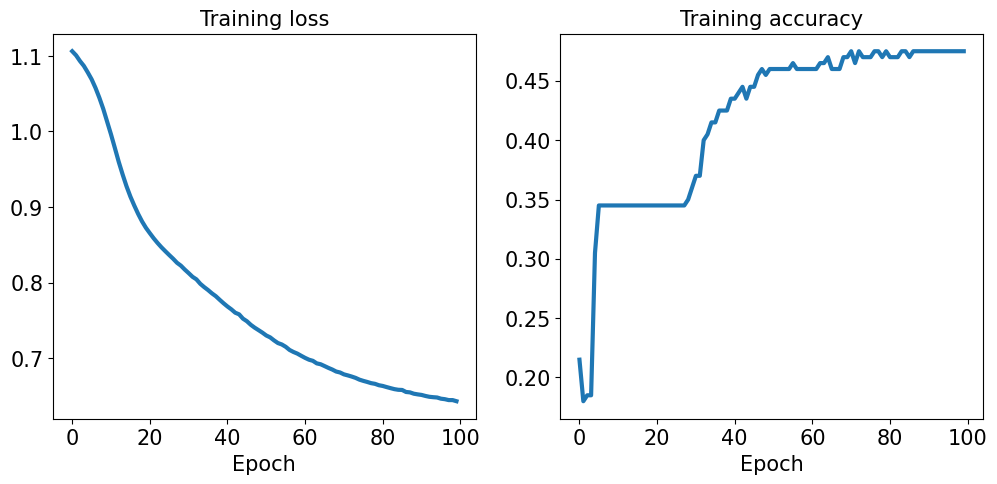

In [31]:
import matplotlib.pyplot as plt 


fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1)

ax.plot(loss_hist, lw=3)
ax.set_title('Training loss', size=15)
ax.set_xlabel('Epoch', size=15)
ax.tick_params(axis='both', which='major', labelsize=15)
ax = fig.add_subplot(1, 2, 2)
ax.plot(accuracy_hist, lw=3)
ax.set_title('Training accuracy', size=15)
ax.set_xlabel('Epoch', size=15)
ax.tick_params(axis='both', which='major', labelsize=15)
plt.show()

###  Evaluating the trained model on the test dataset

In [32]:
X_test_norm = (X_test - np.mean(X_train)) / np.std(X_train)
X_test_norm = torch.from_numpy(X_test_norm).float()
y_test = torch.from_numpy(y_test) 
pred_test = model(X_test_norm)
correct = (torch.argmax(pred_test, dim=1) == y_test).float()
accuracy = correct.mean()
print(f'Test Acc.: {accuracy:.4f}')

Test Acc.: 0.9800


In [33]:
path = 'iris_classifier.pt'
torch.save(model , path)


In [34]:
model_new = torch.load(path)

model_new.eval()


C:\Users\muham\AppData\Local\Temp\ipykernel_6816\189138448.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_new = torch.load(path)


Module(
  (layer1): Linear(in_features=4, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=3, bias=True)
)

In [35]:
pred_test = model_new(X_test_norm)
correct = (torch.argmax(pred_test , dim=1) == y_test).float()
accuracy = correct.mean()
print(f"Test Acc : {accuracy:.4f}") 

Test Acc : 0.9800


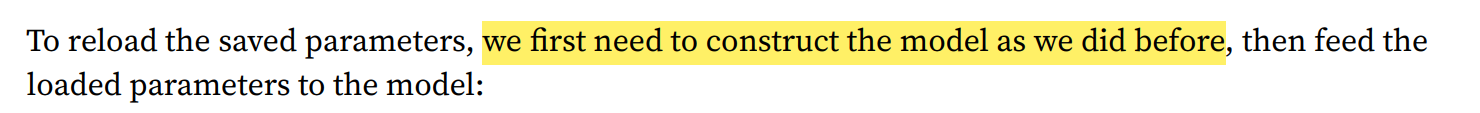

In [36]:
# To save only the learned Paramters 
path = 'iri_classifier_state.pt'
torch.save(model.state_dict() , path )
model_new = Module(input_size, hidden_size, output_size)
model_new.load_state_dict(torch.load(path))

C:\Users\muham\AppData\Local\Temp\ipykernel_6816\879383919.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_new.load_state_dict(torch.load(path))


<All keys matched successfully>

### Choosing activation functions for multilayer neural networks

In [2]:
import numpy as np 

X = np.array([1 , 1.4 , 2.5])
w = np.array([0.4 , 0.3 , 0.5])

def net_input(X , w): 
    return np.dot(X,w)

def logistic(z): 
    return 1.0 / (1.0 + np.exp(-z))

def logistic_activation(X, w): 
    z = net_input(X,w)
    return logistic(z)

print(f'P(y=1|x) = {logistic_activation(X, w):.3f}')

P(y=1|x) = 0.888


In [6]:

W = np.array([[1.1, 1.2, 0.8, 0.4],
[0.2, 0.4, 1.0, 0.2],
[0.6, 1.5, 1.2, 0.7]])

A = np.array([[1, 0.1, 0.4, 0.6]])
Z = np.dot(W, A[0])
y_probas = logistic(Z)
print('Net Input: \n', Z)
print('Output Units:\n', y_probas)


Net Input: 
 [1.78 0.76 1.65]
Output Units:
 [0.85569687 0.68135373 0.83889105]


In [4]:
# it is not very interpretable as it is right now. if we want to predict just label its not an issue but we may want to predict
# the class membership for each class 

y_class = np.argmax(Z , axis=0)
print('Predicted class label: ' , y_class)


Predicted class label:  0


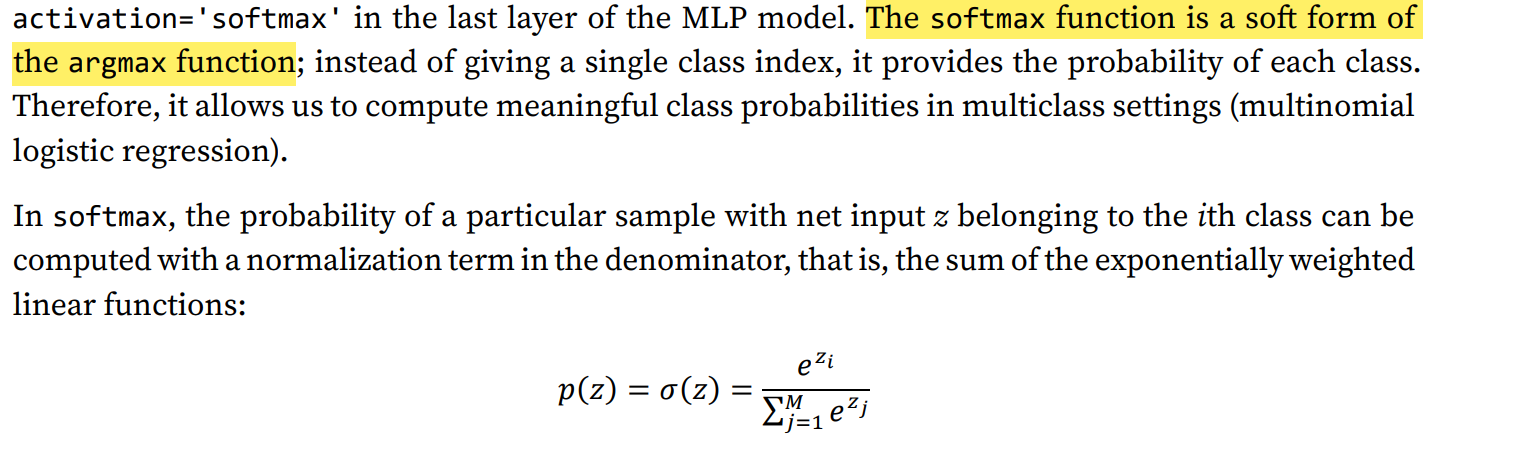

In [8]:
def soft_max(z): 
    return np.exp(z) / (np.sum(np.exp(z)))

y_probas = soft_max(Z)

print('Probabilities: \n ' , y_probas)

np.sum(y_probas) # it sums up to one 


Probabilities: 
  [0.44668973 0.16107406 0.39223621]


np.float64(1.0)

In [10]:
import torch 
torch.softmax(torch.from_numpy(Z), dim=0)

tensor([0.4467, 0.1611, 0.3922], dtype=torch.float64)

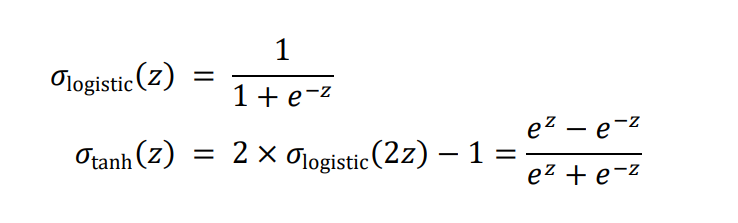

The advantage of the hyperbolic tangent over the logistic function is that it has a broader output 
spectrum ranging in the open interval (–1, 1), which can improve the convergence of the backpropagation algorithm (Neural Networks for Pattern Recognition, C. M. Bishop, Oxford University Press, pages: 
500-501, 1995).

<>:19: SyntaxWarning: invalid escape sequence '\p'
<>:19: SyntaxWarning: invalid escape sequence '\p'
C:\Users\muham\AppData\Local\Temp\ipykernel_49952\2442250366.py:19: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel('activation $\phi(z)$')


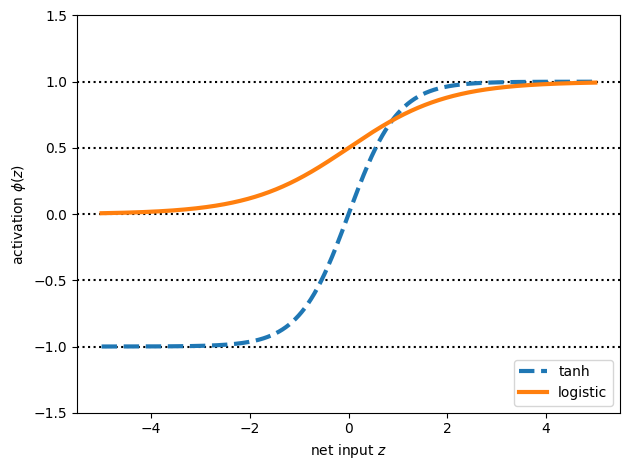

In [11]:
##  hyperbolic tangent (commonly known as tanh)

import numpy as np
import matplotlib.pyplot as plt

def logistic(z):
    return 1 / (1 + np.exp(-z))

def tanh(z):
    e_p = np.exp(z)
    e_m = np.exp(-z)
    return (e_p - e_m) / (e_p + e_m)

z = np.arange(-5, 5, 0.005)
log_act = logistic(z)
tanh_act = tanh(z)
plt.ylim([-1.5, 1.5])
plt.xlabel('net input $z$')
plt.ylabel('activation $\phi(z)$')
plt.axhline(1, color='black', linestyle=':')
plt.axhline(0.5, color='black', linestyle=':')
plt.axhline(0, color='black', linestyle=':')
plt.axhline(-0.5, color='black', linestyle=':')
plt.axhline(-1, color='black', linestyle=':')
plt.plot(z, tanh_act,
         linewidth=3, linestyle='--',
         label='tanh')
plt.plot(z, log_act,
         linewidth=3,
         label='logistic')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [13]:
torch.tanh(torch.from_numpy(Z))

tensor([0.9447, 0.6411, 0.9289], dtype=torch.float64)

In [14]:
from scipy.special import expit
expit(z)

array([0.00669285, 0.00672617, 0.00675966, ..., 0.99320669, 0.99324034,
       0.99327383], shape=(2000,))

Note that using torch.sigmoid(x) produces results that are equivalent to torch.
nn.Sigmoid()(x), which we used earlier. torch.nn.Sigmoid is a class to which you 
can pass in parameters to construct an object in order to control the behavior. In contrast, 
torch.sigmoid is a function.

In [15]:
torch.sigmoid(torch.from_numpy(z))

tensor([0.0067, 0.0067, 0.0068,  ..., 0.9932, 0.9932, 0.9933],
       dtype=torch.float64)

#### Rectified linear unit activation

-- Vanishing Gradient Problem: Gradients becomes very small and training becomes extremely slow. 


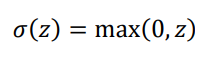

In [16]:
torch.relu(torch.from_numpy(z))

tensor([0.0000, 0.0000, 0.0000,  ..., 4.9850, 4.9900, 4.9950],
       dtype=torch.float64)